<a href="https://colab.research.google.com/github/zildan36/LatihanAnalisis/blob/main/TugasAnalisis2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset Excel
df = pd.read_excel('/content/penjualan_nusantaramart.xlsx')

# Menampilkan 5 data pertama
print(df.head())

   order_id    tanggal    kategori_produk        nama_produk   wilayah  \
0      1146 2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166 2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190 2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219 2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133 2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  


In [ ]:
# Melihat 5 baris pertama
print(df.head())

# Melihat informasi dataset
print(df.info())

# Melihat statistik deskriptif
print(df.describe())


# Menghitung rata-rata transaksi setiap kategori
rata_kategori = df.groupby('kategori_produk')['total'].mean()

# Mengurutkan dari terbesar ke terkecil
print(rata_kategori.sort_values(ascending=False))


# Menghitung mean
print("Mean:", df['total'].mean())

# Menghitung median
print("Median:", df['total'].median())

   order_id    tanggal    kategori_produk        nama_produk   wilayah  \
0      1146 2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166 2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190 2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219 2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133 2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             Non-Nu

/tmp/ipykernel_2439/1207504087.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


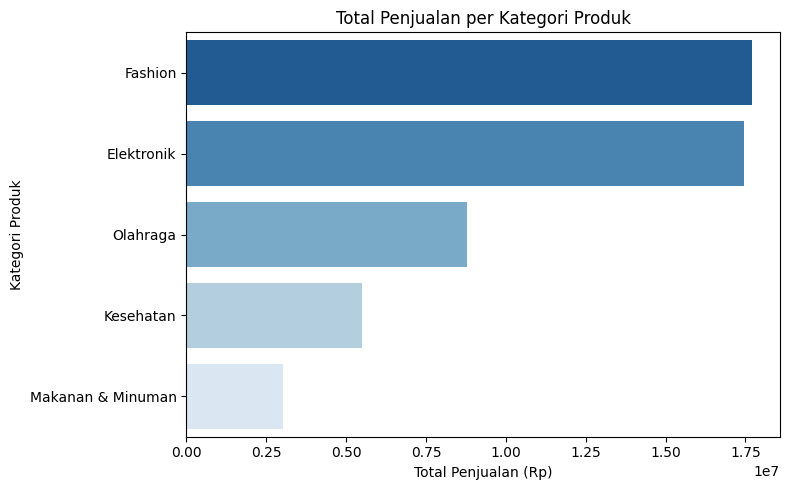

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung total penjualan setiap kategori
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

# Membuat ukuran grafik
plt.figure(figsize=(8,5))

# Membuat grafik batang
sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    palette='Blues_r'
)

# Memberikan judul dan label
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

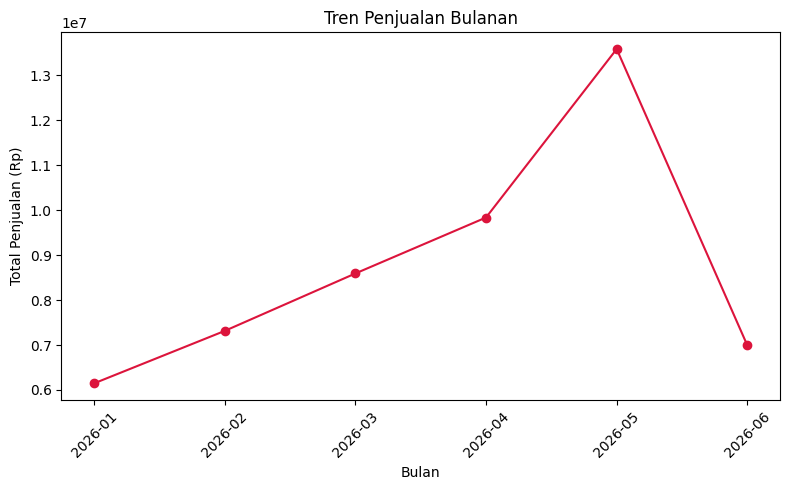

In [ ]:
# Mengubah kolom tanggal menjadi format datetime
df['tanggal'] = pd.to_datetime(df['tanggal'])

# Mengambil informasi bulan dan tahun
df['bulan'] = df['tanggal'].dt.to_period('M')

# Menghitung total penjualan setiap bulan
tren_bulanan = df.groupby('bulan')['total'].sum()

# Membuat grafik garis
plt.figure(figsize=(8,5))

plt.plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson'
)

# Memberikan judul dan label
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

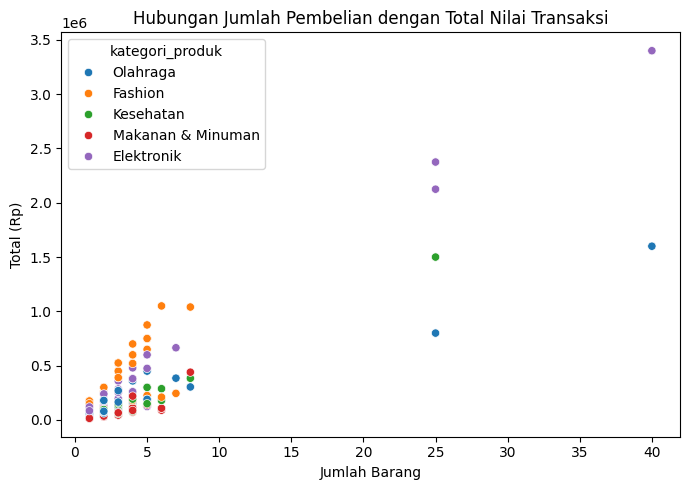

In [ ]:

# Membuat ukuran grafik
plt.figure(figsize=(7,5))

# Membuat scatter plot
sns.scatterplot(
    data=df,
    x='jumlah',
    y='total',
    hue='kategori_produk'
)

# Memberikan judul dan label
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')

plt.tight_layout()
plt.show()


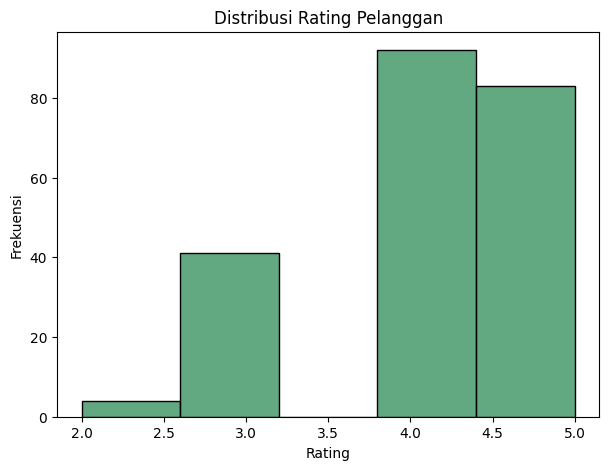

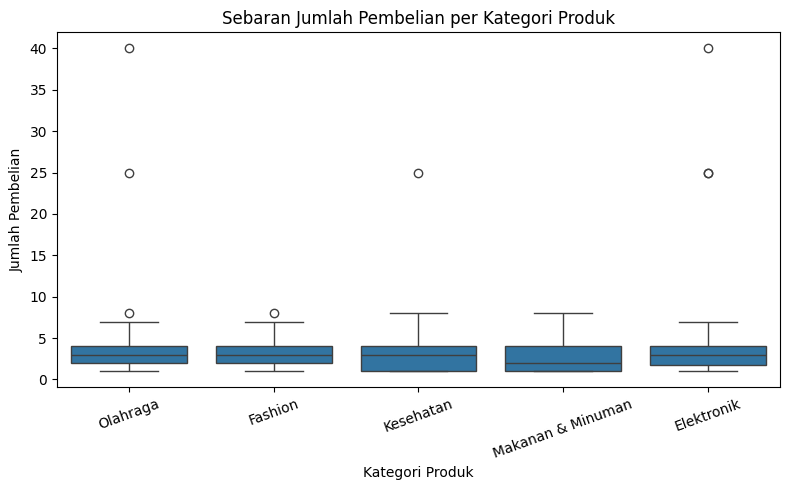

In [ ]:
# Grafik 1: Histogram Rating Pelanggan
plt.figure(figsize=(7,5))

sns.histplot(
    df['rating_pelanggan'],
    bins=5,
    color='seagreen'
)

plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()


# Grafik 2: Boxplot Jumlah Pembelian per Kategori
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='kategori_produk',
    y='jumlah'
)

plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Jumlah Pembelian')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

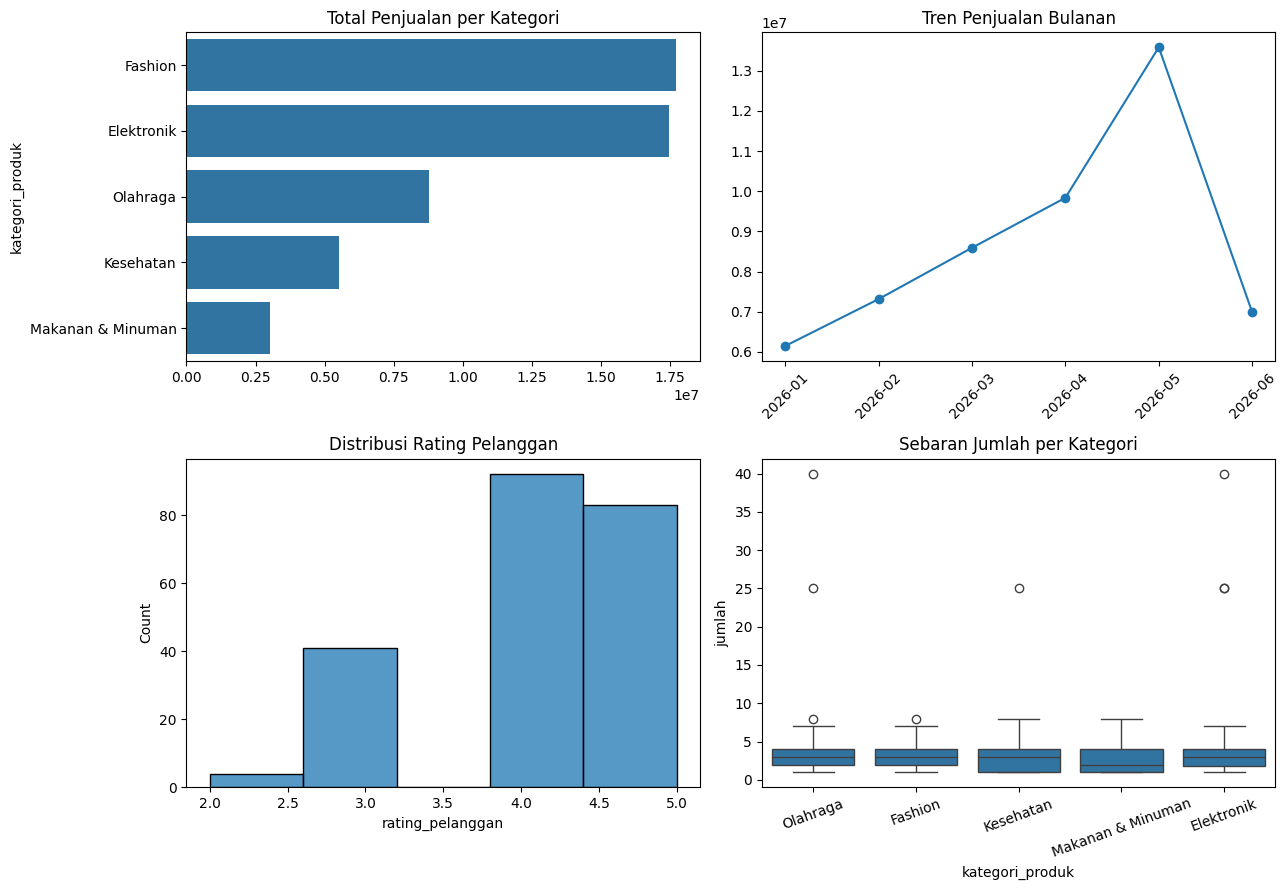

In [ ]:
# Membuat ringkasan total penjualan per kategori
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

# Mengubah tanggal menjadi datetime
df['tanggal'] = pd.to_datetime(df['tanggal'])

# Menghitung total penjualan per bulan
tren_bulanan = df.groupby(
    df['tanggal'].dt.to_period('M')
)['total'].sum()

# Membuat dashboard 2x2
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Grafik 1: Total penjualan per kategori
sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Total Penjualan per Kategori')

# Grafik 2: Tren penjualan bulanan
axes[0, 1].plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o'
)
axes[0, 1].set_title('Tren Penjualan Bulanan')
axes[0, 1].tick_params(axis='x', rotation=45)

# Grafik 3: Distribusi rating pelanggan
sns.histplot(
    df['rating_pelanggan'],
    bins=5,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Distribusi Rating Pelanggan')

# Grafik 4: Sebaran jumlah pembelian
sns.boxplot(
    data=df,
    x='kategori_produk',
    y='jumlah',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Sebaran Jumlah per Kategori')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()